# Earnings Event Volatility

Run from the repository root with the project dependencies installed and the required DBN files in `data/raw/`. <br>This notebook reads local files. Use `download_data.py` separately to acquire missing market data.

# Imports

In [1]:
from pathlib import Path
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

ROOT = next(
    directory for directory in (Path.cwd(), *Path.cwd().parents)
    if (directory / "helpers" / "event_vol_research.py").is_file()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from helpers import event_vol_research as h

In [2]:
# Shared chart style
ink, muted, blue, teal, amber, slate, purple = (
    "#172B3A", "#536675", "#0056AB", "#006B47", "#B34200", "#8095A6", "#82268C"
)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=[blue, amber, purple, teal]),
    "figure.facecolor": "#FFFFFF",
    "axes.facecolor": "#FFFFFF",
    "axes.edgecolor": "#D1DCE4",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelcolor": muted,
    "axes.titlecolor": ink,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.axisbelow": True,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "text.color": ink,
    "xtick.color": muted,
    "ytick.color": muted,
    "grid.color": "#DCE5EB",
    "axes.grid.axis": "y",
    "legend.frameon": False,
    "lines.linewidth": 1.8,
    "lines.markersize": 4,
    "figure.dpi": 120,
})

# Pre/Post-Announcement Analysis

The pre-earnings snapshots use the last valid close-window quote. The post-earnings snapshot is the first opening minute, 09:31 ET on August 27, matching the timing used to interpret the backtest exit.

In [3]:
pre_sessions = ("2026-08-25", "2026-08-26")
post_session = "2026-08-27"
data_dir = ROOT / "data" / "raw"
post_snapshot_time = pd.Timestamp(f"{post_session} 09:31", tz="America/New_York")

results = {
    date: h.run_pipeline(date, data_dir=data_dir, progress=False)
    for date in pre_sessions
}
options, definitions, stock = h.load_data(post_session, data_dir=data_dir, window="open")
option_times = options["ts_recv"] if "ts_recv" in options.columns else options.index
opening_options = options.loc[option_times == post_snapshot_time]
if opening_options.empty:
    raise ValueError(f"No option quotes for the requested snapshot {post_snapshot_time}")
opening_result = h.run_pipeline(
    post_session, data_dir=data_dir, progress=False,
    raw_data=(opening_options, definitions, stock),
)


In [4]:
pipeline_result = results["2026-08-26"]
atm_df = pipeline_result["atm_df"]
surface_df = pipeline_result["surface_df"]
snapshots_by_session = {
    date: h.latest_snapshot(result["atm_df"])
    for date, result in results.items()
}
post_snapshot = opening_result["atm_df"]
if (post_snapshot.empty or not post_snapshot["ts_recv"].eq(post_snapshot_time).all()
        or post_snapshot["total_variance_quadratic"].isna().all()):
    raise ValueError(f"No valid quadratic ATM smile at {post_snapshot_time}")
snapshots_by_session[post_session] = post_snapshot
snapshot = snapshots_by_session["2026-08-26"]
snapshot_time = snapshot["ts_recv"].iloc[0]
snapshot_time_et = snapshot_time.tz_convert("America/New_York")

display(pipeline_result["quality"])

quote_rows                103334
quote_instruments           3476
definition_instruments      3504
common_instruments          3476
quote_only                     0
definition_only               28
crossed                        0
locked                         0
zero_bid                       0
zero_ask                       0
missing_bid_only            4546
missing_ask_only               0
missing_both                   0
merged_rows               103334
missing_definition             0
missing_spot                   0
clean_rows                 98788
missing_forward                0
mid_iv_failures             3678
surface_rows               46298
dtype: int64

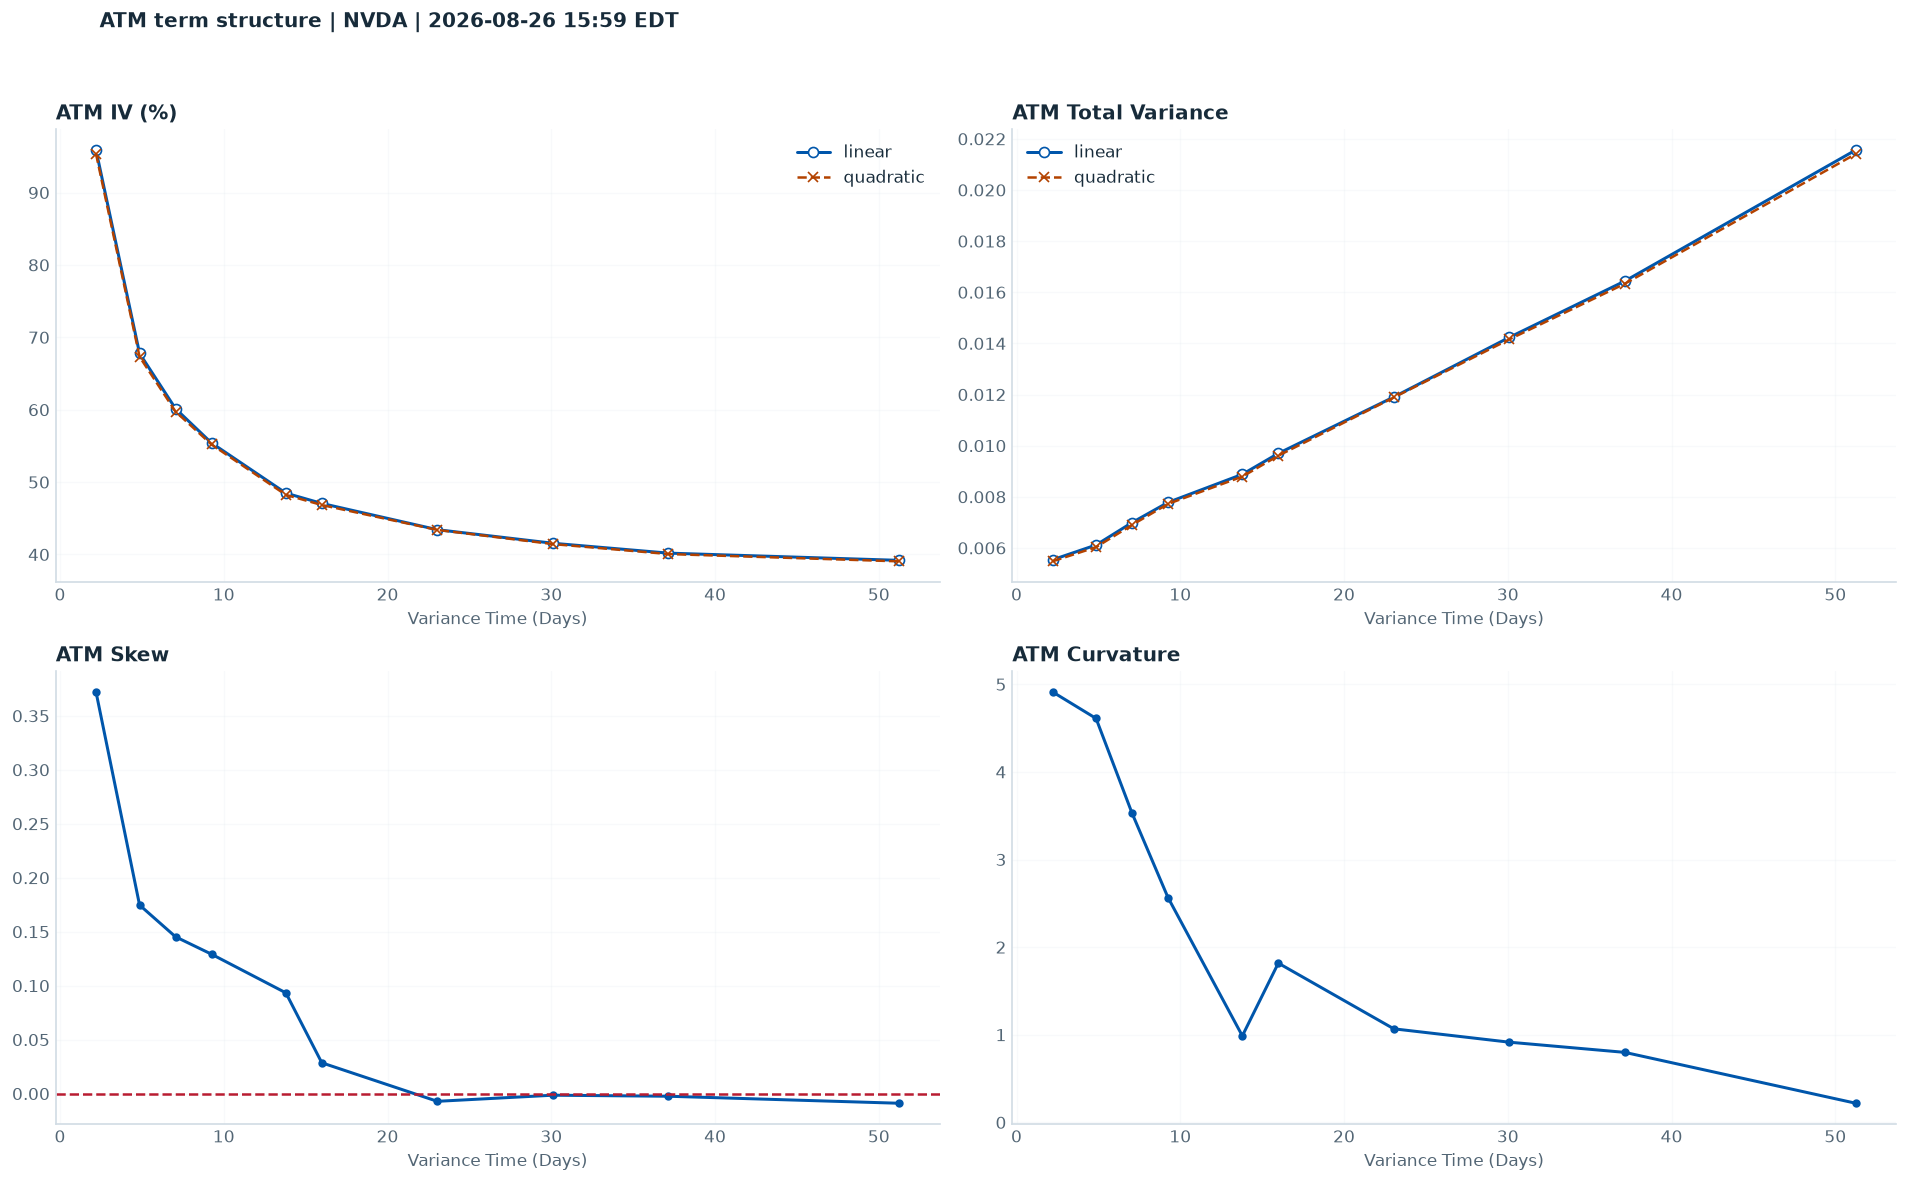

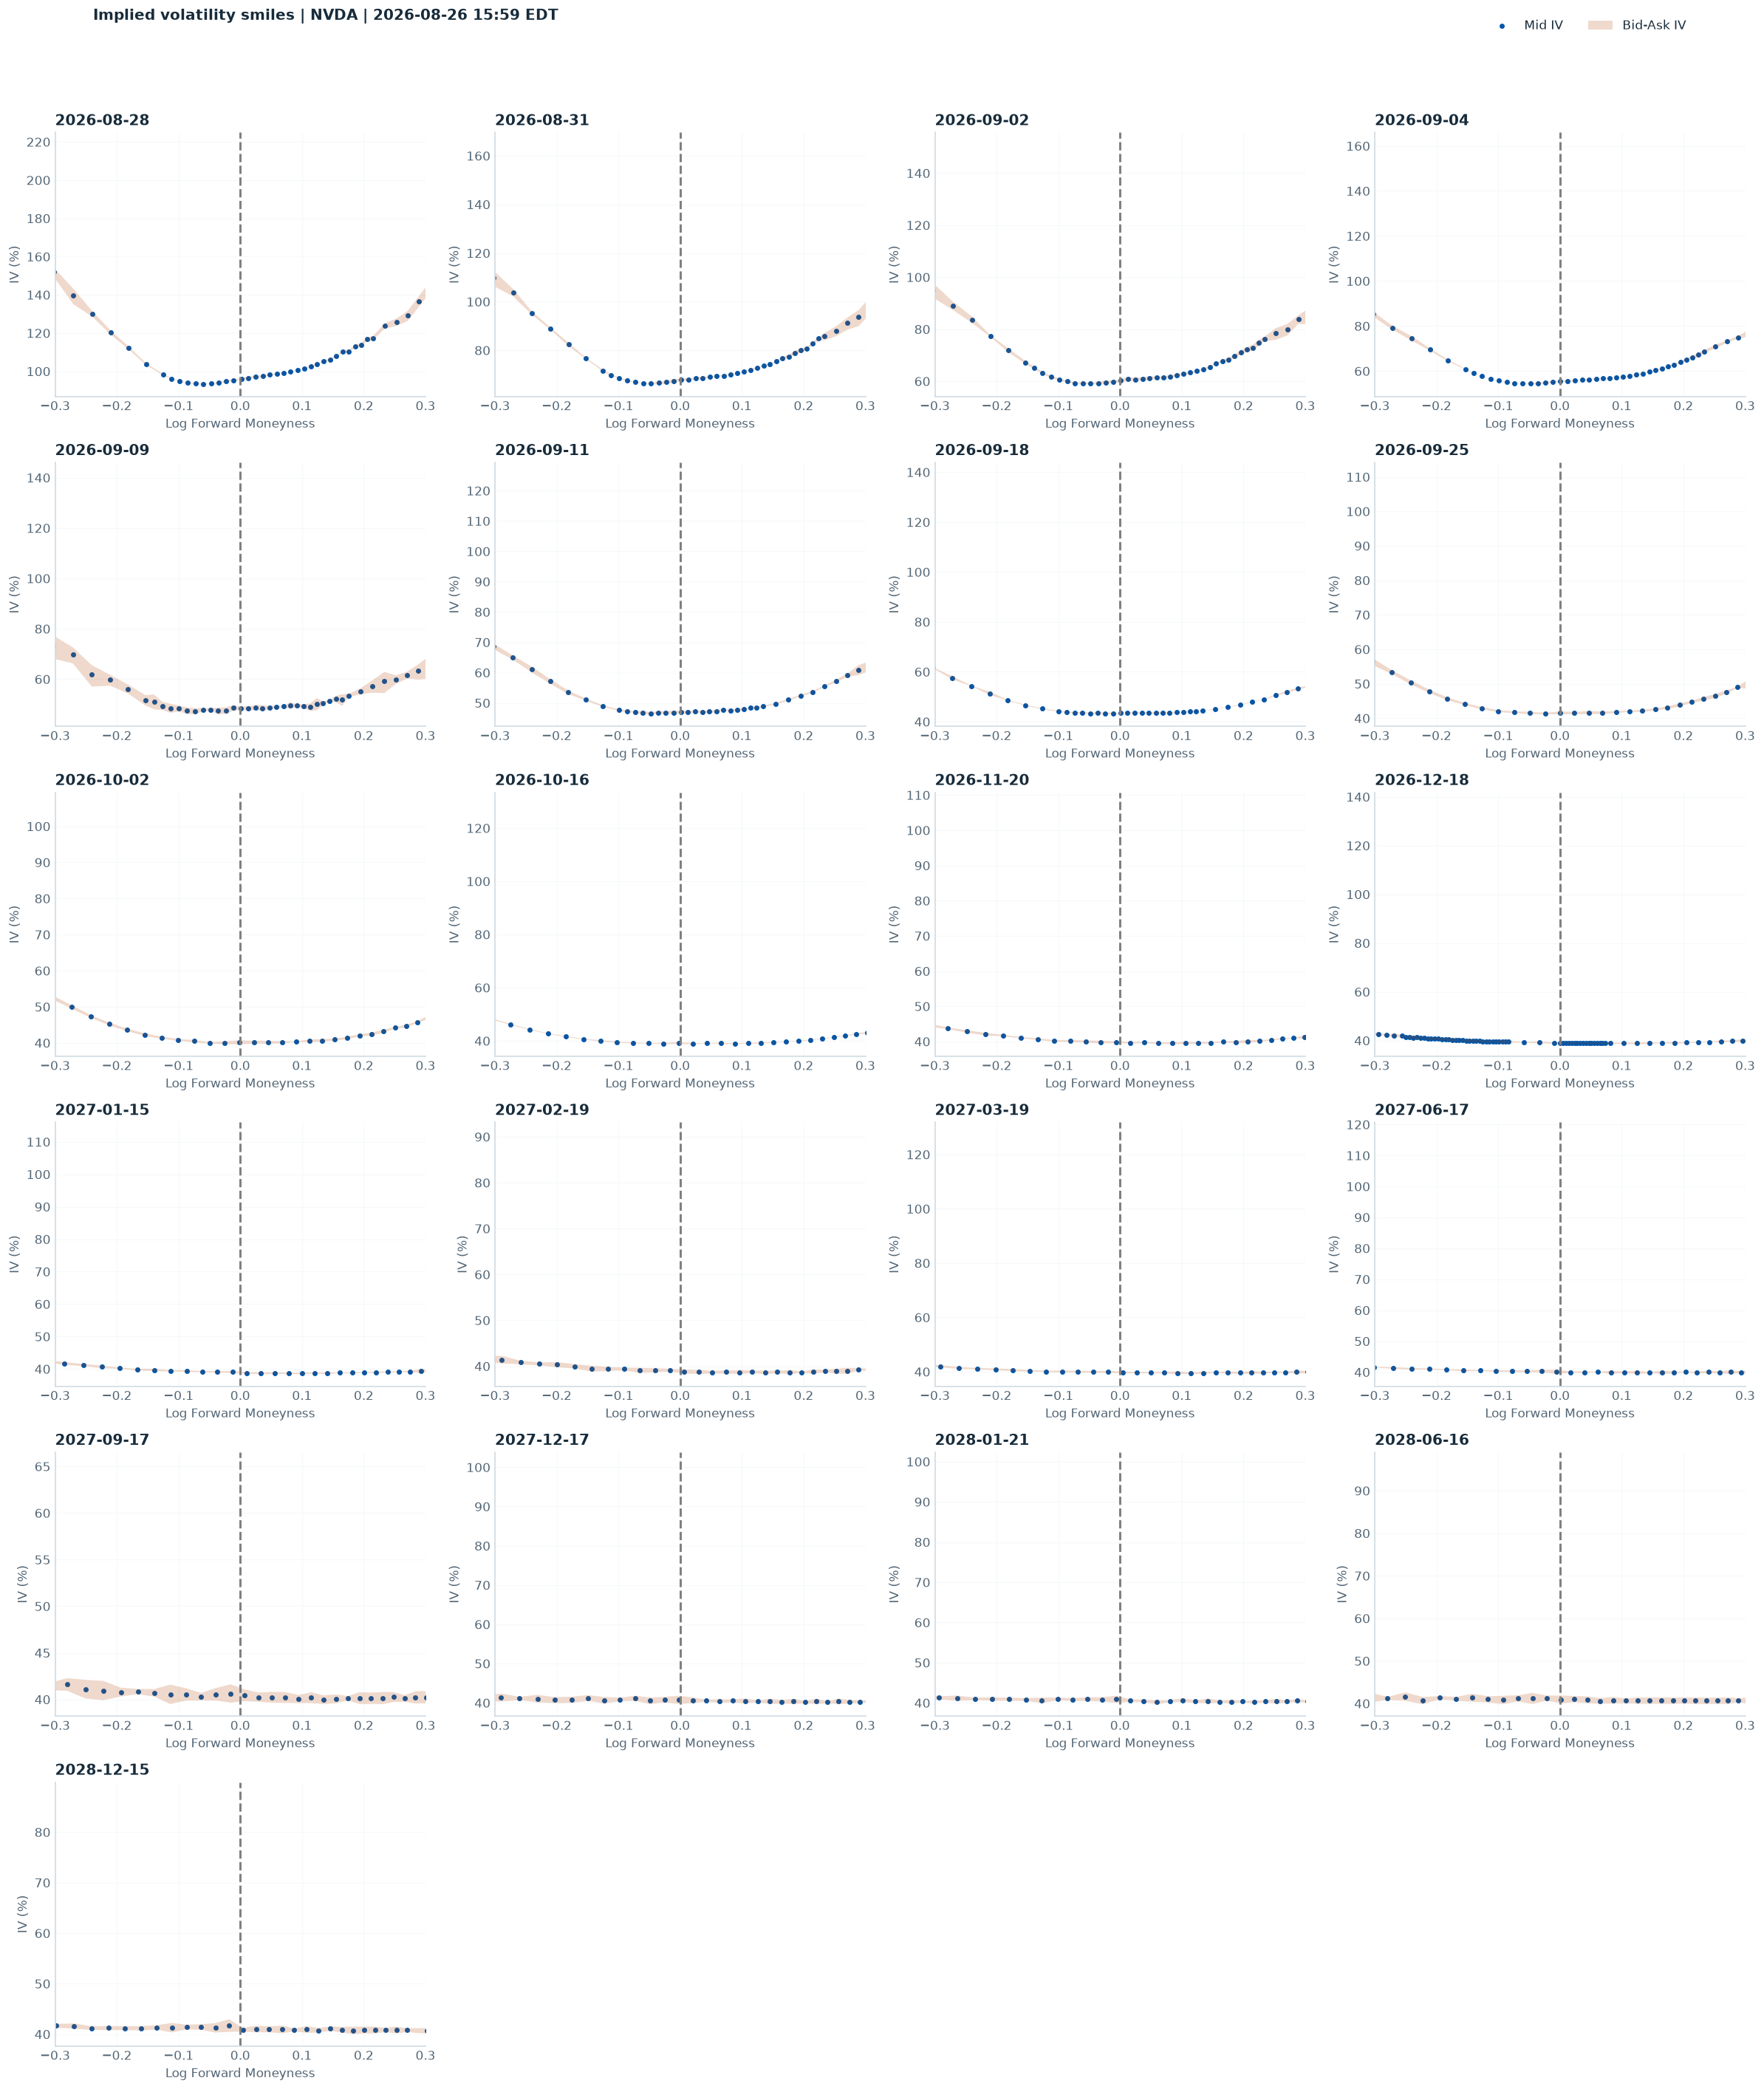

In [5]:
fig, axes = h.plot_atm_term_structure(atm_df, timestamp=snapshot_time, max_dte=60)
for ax in axes[0]:
    linear, quadratic = ax.lines
    linear.set(color=blue, marker="o", markerfacecolor="white", markersize=6)
    quadratic.set(color=amber, linestyle="--", marker="x", markersize=6, linewidth=1.5)
    ax.legend()
axes[1, 0].axhline(0, color="#B91C31", linestyle="--", linewidth=1.5)
fig.suptitle(f"ATM term structure | NVDA | {snapshot_time_et:%Y-%m-%d %H:%M %Z}", x=0.055, ha="left", weight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

fig, axes = h.plot_smiles(surface_df, timestamp=snapshot_time)
fig.suptitle(f"Implied volatility smiles | NVDA | {snapshot_time_et:%Y-%m-%d %H:%M %Z}", x=0.055, ha="left", weight="bold")
visible_axes = [ax for ax in axes.flat if ax.get_visible()]
handles, labels = visible_axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", ncols=2, bbox_to_anchor=(0.96, 0.98))
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

In [6]:
pre_atm_df = pd.concat([
    results["2026-08-25"]["atm_df"],
    results["2026-08-26"]["atm_df"]
], ignore_index=True)

event_ts_df = h.fit_event_series(
    pre_atm_df,
    max_dte=31,
    method="quadratic"
)

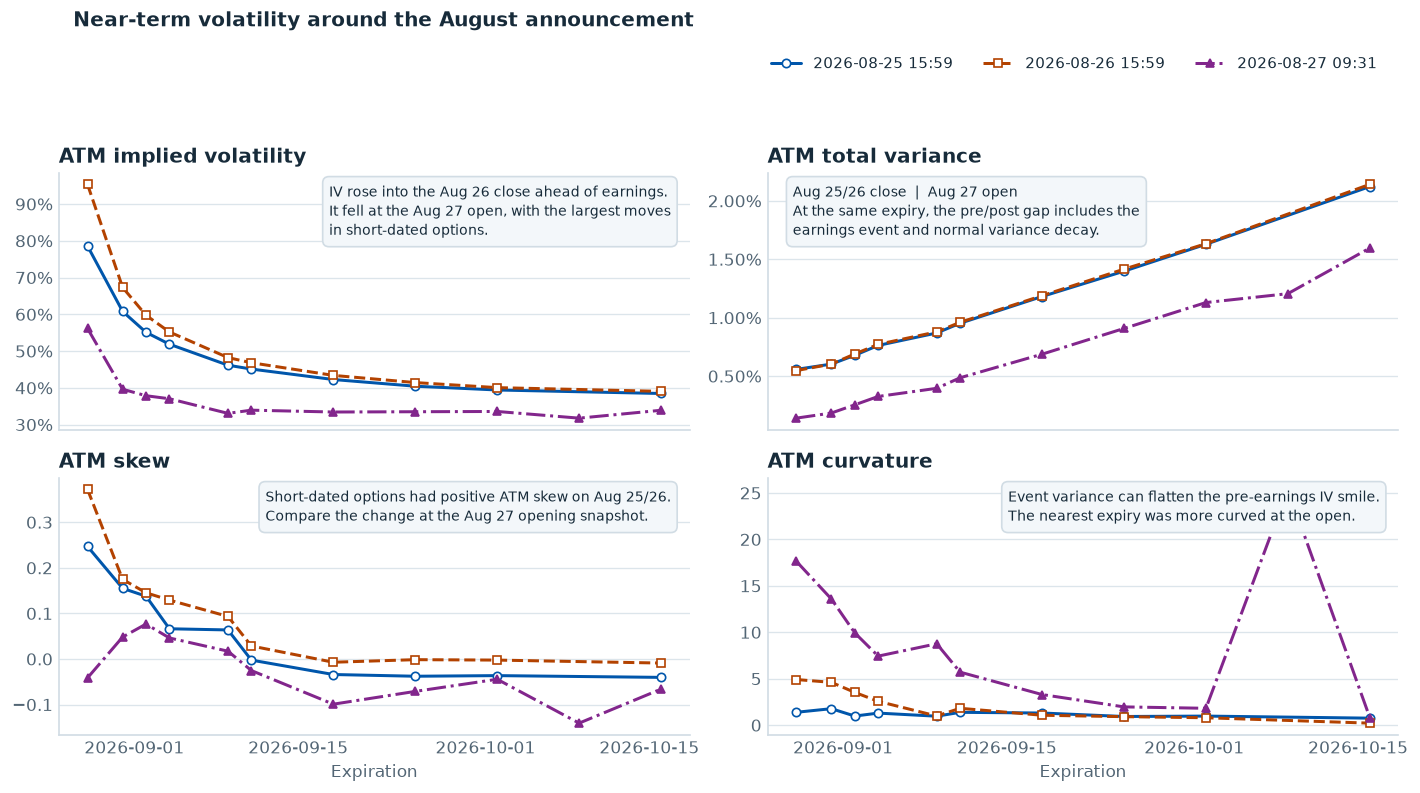

In [7]:
snapshots = pd.concat(
    [frame.assign(date=pd.Timestamp(date).date())
     for date, frame in snapshots_by_session.items()],
    ignore_index=True,
)

fig, axes = plt.subplots(2, 2, figsize=(12, 6.7), sharex=True)
features = {
    "atm_iv_quadratic": ("ATM implied volatility", True),
    "total_variance_quadratic": ("ATM total variance", True),
    "atm_skew": ("ATM skew", False),
    "atm_curvature": ("ATM curvature", False),
}

line_styles = [
    {"color": blue, "linestyle": "-", "marker": "o", "markerfacecolor": "white"},
    {"color": amber, "linestyle": "--", "marker": "s", "markerfacecolor": "white"},
    {"color": purple, "linestyle": "-.", "marker": "^"},
]
for index, (session_date, group) in enumerate(snapshots.groupby("date")):
    line_style = line_styles[index % len(line_styles)]
    sample_time = group["ts_recv"].iloc[0].tz_convert("America/New_York")
    label = f"{session_date} {sample_time:%H:%M}"
    near_term = group.loc[group["T_calendar"] * 365 <= 60].sort_values("expiration")
    for ax, feature in zip(axes.flat, features):
        ax.plot(near_term["expiration"], near_term[feature], label=label,
                markersize=5, **line_style)

for ax, (title, as_percent) in zip(axes.flat, features.values()):
    ax.set_title(title)
    if as_percent:
        ax.yaxis.set_major_formatter(PercentFormatter(1))
for ax in axes[-1]:
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3, maxticks=5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    ax.set_xlabel("Expiration")

chart_notes = [
    (
        axes[0, 0], 0.97, "right",
        "IV rose into the Aug 26 close ahead of earnings.\n"
        "It fell at the Aug 27 open, with the largest moves\n"
        "in short-dated options.",
    ),
    (
        axes[0, 1], 0.04, "left",
        "Aug 25/26 close  |  Aug 27 open\n"
        "At the same expiry, the pre/post gap includes the\n"
        "earnings event and normal variance decay.",
    ),
    (
        axes[1, 0], 0.97, "right",
        "Short-dated options had positive ATM skew on Aug 25/26.\n"
        "Compare the change at the Aug 27 opening snapshot.",
    ),
    (
        axes[1, 1], 0.97, "right",
        "Event variance can flatten the pre-earnings IV smile.\n"
        "The nearest expiry was more curved at the open.",
    ),
]
for ax, x, alignment, note in chart_notes:
    ax.text(
        x, 0.96, note, transform=ax.transAxes, ha=alignment, va="top",
        fontsize=8.5, color=ink, linespacing=1.35, multialignment="left",
        bbox={"boxstyle": "round,pad=0.45", "facecolor": "#F3F7FA",
              "edgecolor": "#D1DCE4"},
    )

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.suptitle("Near-term volatility around the August announcement", x=0.055,
             ha="left", weight="bold")
fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(0.97, 0.94), ncols=3, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.88))
plt.show()

In [8]:

def build_variance_decomposition_table(
    snapshot,
    fit_result,
    method="quadratic",
    max_dte=None
):
    df = snapshot.copy()

    if max_dte is not None:
        df = df[df["T_calendar"] * 365 <= max_dte].copy()

    df = df.sort_values("T_variance").copy()

    df["variance_days"] = df["T_variance"] * 365
    df["total_var"] = df[f"total_variance_{method}"]

    # Variance decomposition
    df["event_var"] = fit_result["event_variance"]
    df["base_var"] = fit_result["base_variance"] * df["T_variance"]
    df["fitted_total_var"] = df["event_var"] + df["base_var"]
    df["residual_var"] = df["total_var"] - df["fitted_total_var"]

    # Normalize by market total variance
    df["event_ratio"] = df["event_var"] / df["total_var"]
    df["base_ratio"] = df["base_var"] / df["total_var"]
    df["residual_ratio"] = df["residual_var"] / df["total_var"]

    cols = [
        "expiration",
        "variance_days",
        "total_var",
        "fitted_total_var",
        "event_var",
        "base_var",
        "residual_var",
        "event_ratio",
        "base_ratio",
        "residual_ratio"
    ]

    return df[cols]

In [9]:
fit_result = h.fit_event_variance(
    snapshot, max_dte=31, method="quadratic"
)

decomp_df = build_variance_decomposition_table(
    snapshot,
    fit_result,
    method="quadratic",
    max_dte=None
)

display(
    decomp_df.style.format({
        "expiration": "{:%Y-%m-%d}",
        "variance_days": "{:.2f}",
        "total_var": "{:.6f}",
        "fitted_total_var": "{:.6f}",
        "event_var": "{:.6f}",
        "base_var": "{:.6f}",
        "residual_var": "{:.6f}",
        "event_ratio": "{:.2%}",
        "base_ratio": "{:.2%}",
        "residual_ratio": "{:.2%}"
    }).background_gradient(
        subset=["event_ratio"], cmap="Oranges"
    ).background_gradient(
        subset=["base_ratio"], cmap="Blues"
    )
)

,expiration,variance_days,total_var,fitted_total_var,event_var,base_var,residual_var,event_ratio,base_ratio,residual_ratio
609,2026-08-28,2.20,0.005475,0.005347,0.004658,0.000689,0.000128,85.09%,12.58%,2.33%
610,2026-08-31,4.86,0.006030,0.006181,0.004658,0.001522,-0.000150,77.25%,25.24%,-2.49%
611,2026-09-02,7.05,0.006898,0.006869,0.004658,0.002210,0.000029,67.53%,32.04%,0.42%
612,2026-09-04,9.25,0.007721,0.007557,0.004658,0.002898,0.000164,60.33%,37.54%,2.13%
613,2026-09-09,13.79,0.008790,0.008979,0.004658,0.004321,-0.000189,53.00%,49.15%,-2.15%
614,2026-09-11,15.99,0.009607,0.009667,0.004658,0.005009,-0.000061,48.49%,52.14%,-0.63%
615,2026-09-18,23.04,0.011885,0.011877,0.004658,0.007219,0.000008,39.20%,60.74%,0.07%
616,2026-09-25,30.09,0.014157,0.014087,0.004658,0.009429,0.000070,32.91%,66.60%,0.50%
617,2026-10-02,37.15,0.016332,0.016297,0.004658,0.011638,0.000036,28.52%,71.26%,0.22%
618,2026-10-16,51.25,0.021413,0.020717,0.004658,0.016058,0.000696,21.76%,74.99%,3.25%


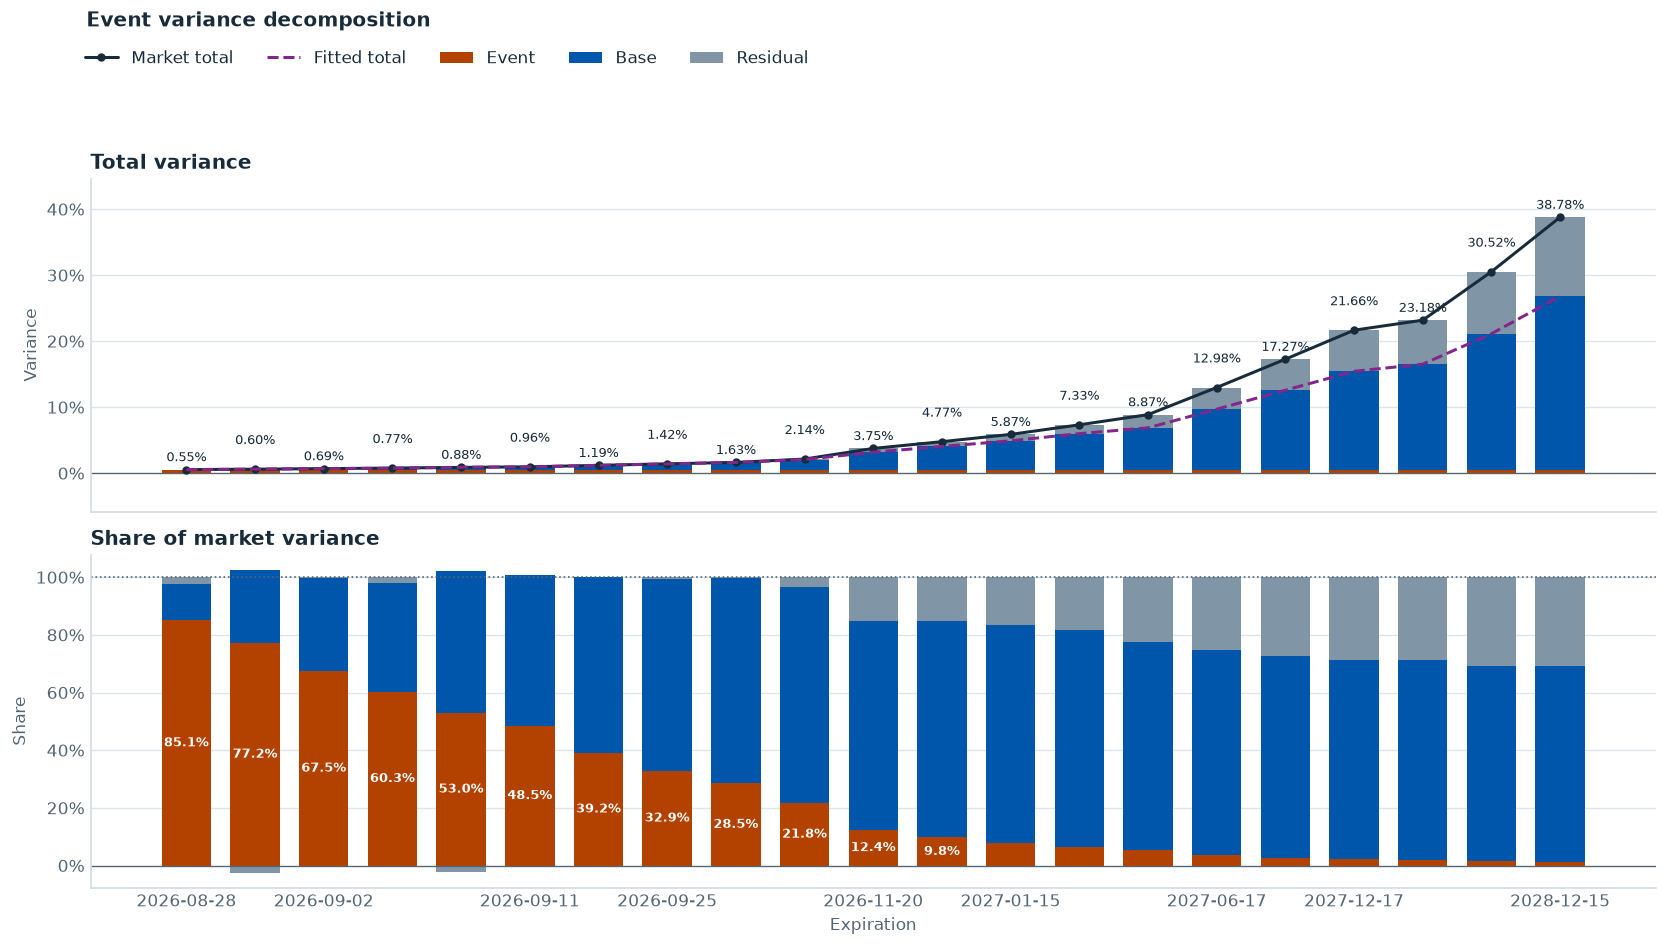

In [10]:
def plot_variance_decomposition(decomp_df):
    df = decomp_df.sort_values("variance_days")
    x = np.arange(len(df))
    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    components = [("Event", amber), ("Base", blue), ("Residual", slate)]
    panels = [
        (["event_var", "base_var", "residual_var"], "Total variance", "Variance"),
        (["event_ratio", "base_ratio", "residual_ratio"], "Share of market variance", "Share"),
    ]

    for ax, (columns, title, ylabel) in zip(axes, panels):
        positive = np.zeros(len(df))
        negative = np.zeros(len(df))
        for column, (label, color) in zip(columns, components):
            values = df[column].to_numpy()
            ax.bar(x, values, bottom=np.where(values >= 0, positive, negative),
                   width=0.72, color=color, label=label)
            positive += np.maximum(values, 0)
            negative += np.minimum(values, 0)
        ax.axhline(0, color=muted, linewidth=0.8)
        ax.set(title=title, ylabel=ylabel)
        ax.yaxis.set_major_formatter(PercentFormatter(1))

    axes[0].plot(x, df["total_var"], "o-", color=ink, label="Market total")
    axes[0].plot(x, df["fitted_total_var"], "--", color=purple, label="Fitted total")
    absolute_components = df[["event_var", "base_var", "residual_var"]]
    positive_stack = absolute_components.clip(lower=0).sum(axis=1)
    label_height = np.maximum.reduce([
        positive_stack.to_numpy(),
        df["total_var"].to_numpy(),
        df["fitted_total_var"].to_numpy(),
    ])
    for index, (total, height) in enumerate(zip(df["total_var"], label_height)):
        if np.isfinite(height):
            axes[0].annotate(f"{total:.2%}", (index, height),
                             xytext=(0, 5 + 10 * (index % 2)),
                             textcoords="offset points", ha="center",
                             fontsize=8, color=ink)
    axes[0].margins(y=0.15)

    axes[1].axhline(1, color=muted, linewidth=1, linestyle=":")
    # The adjacent table carries the exact values for thinner segments.
    for index, ratio in enumerate(df["event_ratio"]):
        if np.isfinite(ratio) and abs(ratio) >= 0.09:
            axes[1].text(index, ratio / 2, f"{ratio:.1%}", color="white",
                         ha="center", va="center", fontsize=8, weight="bold")
    ticks = np.unique(np.linspace(0, len(df) - 1, min(len(df), 9), dtype=int))
    axes[1].set_xticks(ticks, df["expiration"].iloc[ticks].dt.strftime("%Y-%m-%d"))
    axes[1].set_xlabel("Expiration")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.suptitle("Event variance decomposition", x=0.055, ha="left", weight="bold")
    fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.045, 0.955), ncols=5)
    fig.tight_layout(rect=(0, 0, 1, 0.89))
    plt.show()


plot_variance_decomposition(decomp_df)

In [11]:
# Yahoo Finance regular-session OHLCV, cached locally.
daily_path = ROOT / "data" / "raw" / "NVDA_daily_ohlcv.csv"
pre_session, post_session = "2026-08-26", "2026-08-27"
realized_jump = np.nan

if daily_path.is_file():
    daily_df = pd.read_csv(daily_path, dtype={"session_date": str}).set_index(
        "session_date"
    )
    if not daily_df.index.is_unique:
        raise ValueError("Daily OHLCV contains duplicate trading dates.")
    missing_sessions = [day for day in (pre_session, post_session) if day not in daily_df.index]
    if missing_sessions:
        print(f"Realized jump comparison skipped: missing sessions {missing_sessions}.")
    else:
        pre_close = daily_df.at[pre_session, "close"]
        post_open = daily_df.at[post_session, "open"]
        realized_jump = np.log(post_open / pre_close)
else:
    print(f"Realized jump comparison skipped: {daily_path} is missing.")

In [12]:
if np.isfinite(realized_jump):
    realized_event_var = realized_jump**2

    implied_event_var = fit_result["event_variance"]

    comparison = pd.Series({
        "Implied Event Move": np.sqrt(implied_event_var),
        "Realized Event Jump": realized_jump,
        "Implied Event Variance": implied_event_var,
        "Realized Event Variance": realized_event_var,
        "Variance Premium": implied_event_var - realized_event_var
    })

    display(comparison.map(lambda x: f"{x:.4%}"))

Implied Event Move         6.8253%
Realized Event Jump        6.1057%
Implied Event Variance     0.4658%
Realized Event Variance    0.3728%
Variance Premium           0.0931%
dtype: str

In [13]:
def estimate_event_variance_pre_post(
    pre_df,
    post_df,
    base_variance,
    method="quadratic"
):
    cols = [
        "expiration",
        "T_calendar",
        "T_variance",
        f"total_variance_{method}"
    ]

    df = pre_df[cols].merge(
        post_df[cols],
        on="expiration",
        suffixes=("_pre", "_post"),
        how="inner",
        validate="one_to_one"
    )

    df["variance_time_decay"] = (
        df["T_variance_pre"] - df["T_variance_post"]
    )

    df["total_var_pre"] = df[f"total_variance_{method}_pre"]
    df["total_var_post"] = df[f"total_variance_{method}_post"]

    df["total_var_reduction"] = (
        df["total_var_pre"] - df["total_var_post"]
    )

    df["base_var_decay"] = (
        base_variance * df["variance_time_decay"]
    )

    df["event_variance"] = (
        df["total_var_reduction"] - df["base_var_decay"]
    )

    df["event_move"] = np.sqrt(
        df["event_variance"].where(df["event_variance"] >= 0)
    )

    df["event_ratio"] = (
        df["event_variance"] / df["total_var_pre"]
    )

    df["dte"] = df["T_calendar_pre"] * 365

    return df.sort_values("expiration").reset_index(drop=True)

In [14]:
pre_df = snapshots[
    snapshots["date"] == pd.Timestamp("2026-08-26").date()
].copy()

post_df = snapshots[
    snapshots["date"] == pd.Timestamp("2026-08-27").date()
].copy()

# Refit Method A using the selected 8/26 snapshot
fit_result = h.fit_event_variance(
    pre_df,
    max_dte=31,
    method="quadratic"
)

event_comparison_df = estimate_event_variance_pre_post(
    pre_df,
    post_df,
    base_variance=fit_result["base_variance"]
)

event_comparison_df["event_variance_ols"] = (
    fit_result["event_variance"]
)

event_comparison_df["estimation_difference"] = (
    event_comparison_df["event_variance"]
    - event_comparison_df["event_variance_ols"]
)

In [15]:
cols = [
    "expiration",
    "dte",
    "total_var_pre",
    "total_var_post",
    "total_var_reduction",
    "base_var_decay",
    "event_variance",
    "event_variance_ols",
    "estimation_difference",
    "event_move",
    "event_ratio"
]

formats = {
    col: "{:.4%}"
    for col in cols
    if col not in ["expiration", "dte"]
}

formats.update({
    "expiration": "{:%Y-%m-%d}",
    "dte": "{:.2f}"
})

display(
    event_comparison_df[cols]
    .style.format(formats)
    .background_gradient(
        subset=["estimation_difference"],
        cmap="RdBu_r"
    )
)

,expiration,dte,total_var_pre,total_var_post,total_var_reduction,base_var_decay,event_variance,event_variance_ols,estimation_difference,event_move,event_ratio
0,2026-08-28,2.00,0.5475%,0.1405%,0.4070%,0.0179%,0.3890%,0.4658%,-0.0768%,6.2373%,71.0589%
1,2026-08-31,5.00,0.6030%,0.1843%,0.4187%,0.0179%,0.4008%,0.4658%,-0.0651%,6.3306%,66.4574%
2,2026-09-02,7.00,0.6898%,0.2546%,0.4352%,0.0179%,0.4173%,0.4658%,-0.0485%,6.4599%,60.4955%
3,2026-09-04,9.00,0.7721%,0.3262%,0.4460%,0.0179%,0.4280%,0.4658%,-0.0378%,6.5425%,55.4365%
4,2026-09-09,14.00,0.8790%,0.3959%,0.4831%,0.0179%,0.4652%,0.4658%,-0.0006%,6.8206%,52.9217%
5,2026-09-11,16.00,0.9607%,0.4862%,0.4744%,0.0179%,0.4565%,0.4658%,-0.0093%,6.7566%,47.5197%
6,2026-09-18,23.00,1.1885%,0.6880%,0.5006%,0.0179%,0.4826%,0.4658%,0.0168%,6.9471%,40.6072%
7,2026-09-25,30.00,1.4157%,0.9080%,0.5077%,0.0179%,0.4898%,0.4658%,0.0239%,6.9984%,34.5960%
8,2026-10-02,37.00,1.6332%,1.1298%,0.5034%,0.0179%,0.4855%,0.4658%,0.0196%,6.9677%,29.7252%
9,2026-10-16,51.00,2.1413%,1.5962%,0.5451%,0.0179%,0.5271%,0.4658%,0.0613%,7.2604%,24.6178%


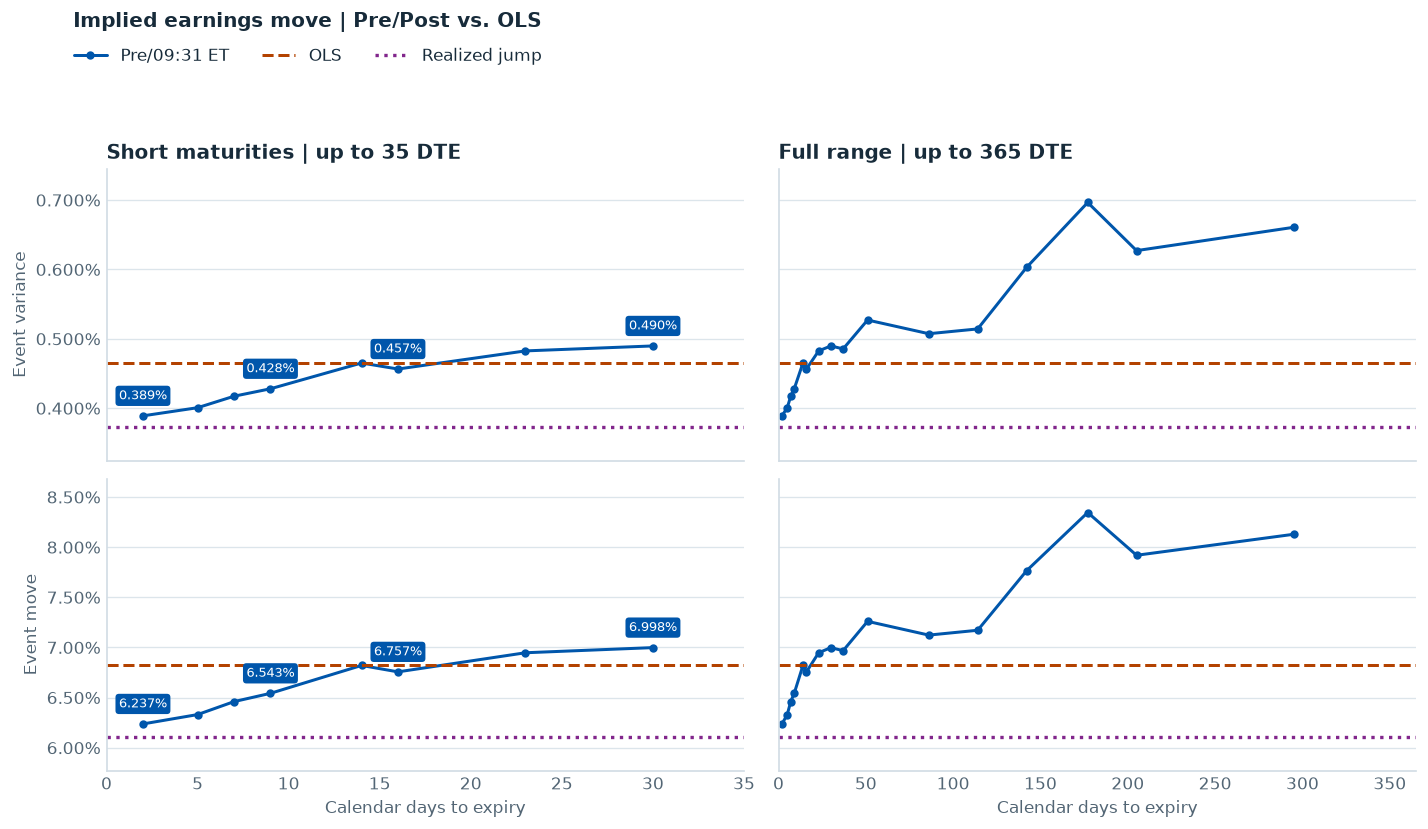

In [16]:
comparison_df = event_comparison_df.query("dte <= 365").sort_values("dte")
short_dte = 35
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex="col", sharey="row")
metrics = [
    ("event_variance", fit_result["event_variance"], realized_jump**2, "Event variance"),
    ("event_move", fit_result["event_move"], abs(realized_jump), "Event move"),
]

for row, (column, ols_value, realized_value, label) in enumerate(metrics):
    for ax, limit in zip(axes[row], (short_dte, 365)):
        panel = comparison_df.loc[comparison_df["dte"] <= limit]
        ax.plot(panel["dte"], panel[column], "o-", color=blue, label="Pre/09:31 ET")
        if np.isfinite(ols_value):
            ax.axhline(ols_value, color=amber, linestyle="--", label="OLS")
        if np.isfinite(realized_value):
            ax.axhline(realized_value, color=purple, linestyle=":", linewidth=2, label="Realized jump")
        ax.set_xlim(0, limit)
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.margins(y=0.15)
        if limit == short_dte:
            valid = panel.dropna(subset=[column])
            if not valid.empty:
                # Label representative points with enough horizontal space.
                last_labeled_dte = -np.inf
                for point in valid.itertuples():
                    if point.dte - last_labeled_dte < 7:
                        continue
                    value = getattr(point, column)
                    ax.annotate(
                        f"{value:.3%}", (point.dte, value), xytext=(0, 8),
                        textcoords="offset points", ha="center", va="bottom",
                        fontsize=8, color="white",
                        bbox={"boxstyle": "round,pad=0.26", "facecolor": blue,
                              "edgecolor": "none"},
                    )
                    last_labeled_dte = point.dte
    axes[row, 0].set_ylabel(label)

axes[0, 0].set_title(f"Short maturities | up to {short_dte} DTE")
axes[0, 1].set_title("Full range | up to 365 DTE")
for ax in axes[-1]:
    ax.set_xlabel("Calendar days to expiry")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.suptitle("Implied earnings move | Pre/Post vs. OLS", x=0.055, ha="left", weight="bold")
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.045, 0.955), ncols=3)
fig.tight_layout(rect=(0, 0, 1, 0.89))
plt.show()